# 03 Global LightGBM model
One model for all series, trained on lag / rolling / calendar / event / SNAP / price features.
Direct 28-day forecasting: every lag and rolling feature is at least 28 days old, so a model trained on history can forecast all 28 days at once with no leakage.
Evaluated on the same 5 rolling folds as the baselines, and compared against the best of them.

In [1]:
import sys
sys.path.append("..")
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

PROC, FIG, REP = Path("../data/processed"), Path("../reports/figures"), Path("../reports")
STORE = "CA_1"
H, N_FOLDS = 28, 5

TRAIN_DAYS = 540     # training window per fold (smaller = faster, try 365 first if slow)
N_ROUNDS = 400
PARAMS = dict(
    objective="tweedie", tweedie_variance_power=1.1,   # count data with many zeros
    learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
    lambda_l2=0.1, verbosity=-1, seed=42,
)

C:\Users\Ahmed's PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\basic.py:30: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.4)
  import scipy.sparse


## 1. Load data into series x days matrices

In [2]:
long = pd.read_parquet(PROC / f"{STORE.lower()}_long.parquet")
sales = long.pivot(index="id", columns="date", values="sales")
ids, dates = sales.index.to_numpy(), sales.columns

def wide(col):
    return long.pivot(index="id", columns="date", values=col).reindex(index=sales.index, columns=sales.columns)

Y64 = sales.to_numpy(dtype=float)          # for evaluation
Y = Y64.astype(np.float32)                 # for features
P = wide("sell_price").to_numpy(dtype=np.float32)

meta = long.drop_duplicates("id").set_index("id").loc[ids]
cat_code = meta["cat_id"].astype("category").cat.codes.to_numpy()
dept_code = meta["dept_id"].astype("category").cat.codes.to_numpy()

cal = long.drop_duplicates("date").set_index("date").loc[dates]
snap_by_state = {s: cal[f"snap_{s}"].to_numpy(dtype=np.float32) for s in ["CA", "TX", "WI"]}
S = np.vstack([snap_by_state[s] for s in meta["state_id"]])

dow = dates.dayofweek.to_numpy()
dom = dates.day.to_numpy()
month = dates.month.to_numpy()
has_event = cal["event_name_1"].notna().to_numpy().astype(int)
event_type = cal["event_type_1"].astype("category").cat.codes.to_numpy() + 1   # 0 = no event
print(Y.shape, "series x days")

(3049, 1941) series x days


C:\Users\Ahmed's PC\AppData\Local\Temp\ipykernel_47856\3115622238.py:20: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = dates.dayofweek.to_numpy()


## 2. Features (computed on the whole matrix at once, fast)
Sales-based features are shifted by 28 days. Price and SNAP are known in advance, so they are not shifted.

In [3]:
def shift(A, k):
    out = np.full(A.shape, np.nan, dtype=np.float32)
    out[:, k:] = A[:, :-k]
    return out

def rolling_sum(A, w):
    cs = np.cumsum(A, axis=1, dtype=np.float64)
    out = np.full(A.shape, np.nan, dtype=np.float64)
    out[:, w - 1:] = cs[:, w - 1:] - np.concatenate([np.zeros((A.shape[0], 1)), cs[:, :-w]], axis=1)
    return out

def rolling_mean(A, w):
    return (rolling_sum(A, w) / w).astype(np.float32)

def rolling_std(A, w):
    m = rolling_sum(A, w) / w
    m2 = rolling_sum(A.astype(np.float64) ** 2, w) / w
    return np.sqrt(np.clip(m2 - m ** 2, 0, None)).astype(np.float32)

feat = {}
for k in [28, 35, 42, 49, 56]:
    feat[f"lag_{k}"] = shift(Y, k)
for w in [7, 14, 28, 56]:
    feat[f"rmean_{w}"] = shift(rolling_mean(Y, w), H)
feat["rstd_28"] = shift(rolling_std(Y, 28), H)
nzm = (Y > 0).astype(np.float32)
feat["nz_7"] = shift(rolling_mean(nzm, 7), H)
feat["nz_28"] = shift(rolling_mean(nzm, 28), H)
feat["dow_mean_4w"] = (feat["lag_28"] + feat["lag_35"] + feat["lag_42"] + feat["lag_49"]) / 4

Pz, valid = np.nan_to_num(P, nan=0.0), (~np.isnan(P)).astype(np.float32)
price_avg_56 = rolling_sum(Pz, 56) / np.maximum(rolling_sum(valid, 56), 1)
feat["price"] = P
feat["price_rel_56"] = (P / price_avg_56).astype(np.float32)
feat["price_chg_28"] = (P / shift(P, 28)).astype(np.float32)

CATS = ["cat", "dept", "dow", "event_type"]
FIRST = 84   # first day where every lag / rolling feature exists

def make_frame(d0, d1):
    n, nd = len(ids), d1 - d0
    cols = {name: A[:, d0:d1].ravel() for name, A in feat.items()}
    cols["snap"] = S[:, d0:d1].ravel()
    cols["dow"] = np.tile(dow[d0:d1], n)
    cols["dom"] = np.tile(dom[d0:d1], n)
    cols["month"] = np.tile(month[d0:d1], n)
    cols["has_event"] = np.tile(has_event[d0:d1], n)
    cols["event_type"] = np.tile(event_type[d0:d1], n)
    cols["cat"] = np.repeat(cat_code, nd)
    cols["dept"] = np.repeat(dept_code, nd)
    return pd.DataFrame(cols), Y[:, d0:d1].ravel()

## 3. Reference baselines (same functions as notebook 02, for a fair side-by-side)

In [4]:
def f_ma(w):
    return lambda tr: np.repeat(tr[:, -w:].mean(axis=1, keepdims=True), H, axis=1)

def f_dow_mean(weeks=4):
    def f(tr):
        b = tr[:, -7 * weeks:].reshape(tr.shape[0], weeks, 7).mean(axis=1)
        return np.tile(b, (1, H // 7))
    return f

def f_tsb(alpha=0.1, beta=0.1):
    def f(tr):
        n, T = tr.shape
        nz = tr > 0
        cnt = nz.sum(axis=1)
        z = np.where(cnt > 0, np.where(nz, tr, 0).sum(axis=1) / np.maximum(cnt, 1), 0.0)
        p = cnt / T
        for t in range(T):
            d, hit = tr[:, t], tr[:, t] > 0
            z = np.where(hit, alpha * d + (1 - alpha) * z, z)
            p = beta * hit + (1 - beta) * p
        return np.repeat((p * z)[:, None], H, axis=1)
    return f

refs = {"ma_28": f_ma(28), "dow_mean_4w": f_dow_mean(4), "tsb": f_tsb()}

def rmsse_scale(tr):
    scale = np.full(tr.shape[0], np.nan)
    for i in range(tr.shape[0]):
        nz = np.flatnonzero(tr[i])
        if len(nz) < 2:
            continue
        s = np.mean(np.diff(tr[i, nz[0]:]) ** 2)
        if s > 0:
            scale[i] = s
    return scale

def demand_classes(A):
    out = []
    for row in A:
        nz = np.flatnonzero(row)
        if len(nz) == 0:
            out.append("no sales"); continue
        tr = row[nz[0]:]; d = tr[tr > 0]
        adi = len(tr) / len(d)
        cv2 = (d.std() / d.mean()) ** 2 if len(d) > 1 else 0.0
        if adi < 1.32:
            out.append("smooth" if cv2 < 0.49 else "erratic")
        else:
            out.append("intermittent" if cv2 < 0.49 else "lumpy")
    return np.array(out)

## 4. Train and forecast on each fold
One model per fold, trained only on days before the forecast origin.
Rows where the item was not on sale yet (no price) are dropped from training, and forecast as 0 when unpriced.

In [5]:
T_all = Y.shape[1]
origins = [T_all - H * k for k in range(N_FOLDS, 0, -1)]
print("forecast origins:", origins)

records, last = [], {}
for fold, o in enumerate(origins):
    t0 = time.time()
    d0 = max(FIRST, o - TRAIN_DAYS)
    X, y = make_frame(d0, o)
    keep = ~np.isnan(X["price"].to_numpy())
    dtrain = lgb.Dataset(X[keep], y[keep], categorical_feature=CATS)
    model = lgb.train(PARAMS, dtrain, num_boost_round=N_ROUNDS)

    Xt, _ = make_frame(o, o + H)
    pred = model.predict(Xt)
    pred = np.where(np.isnan(Xt["price"].to_numpy()), 0.0, pred)
    F_lgb = np.clip(pred, 0, None).reshape(len(ids), H)

    tr, te = Y64[:, :o], Y64[:, o:o + H]
    scale = rmsse_scale(tr)
    weight = (Y64[:, o - 28:o] * np.nan_to_num(P[:, o - 28:o])).sum(axis=1)
    forecasts = {"lightgbm": F_lgb, **{k: fn(tr) for k, fn in refs.items()}}
    for name, F in forecasts.items():
        records.append(pd.DataFrame({
            "id": ids, "fold": fold, "model": name,
            "rmsse": np.sqrt(((te - F) ** 2).mean(axis=1) / scale),
            "mae": np.abs(te - F).mean(axis=1),
            "bias": (F - te).mean(axis=1),
            "weight": weight,
        }))
    last = {"model": model, "forecasts": forecasts, "origin": o}
    print(f"fold {fold}: trained on {int(keep.sum()):,} rows in {time.time() - t0:.0f}s")

res = pd.concat(records, ignore_index=True)
classes = pd.Series(demand_classes(Y64[:, :origins[0]]), index=ids, name="class")
res = res.join(classes, on="id").join(meta[["cat_id"]], on="id")
ok = res.dropna(subset=["rmsse"]).copy()
ok["wr"] = ok["rmsse"] * ok["weight"]

forecast origins: [1801, 1829, 1857, 1885, 1913]
fold 0: trained on 1,623,394 rows in 15s
fold 1: trained on 1,627,412 rows in 18s
fold 2: trained on 1,630,963 rows in 17s
fold 3: trained on 1,634,062 rows in 16s
fold 4: trained on 1,636,711 rows in 15s


## 5. Results (lower is better)

In [6]:
g = ok.groupby("model")
summary = pd.DataFrame({
    "rmsse": g["rmsse"].mean(),
    "wrmsse": g["wr"].sum() / g["weight"].sum(),
    "mae": g["mae"].mean(),
    "bias": g["bias"].mean(),
}).sort_values("wrmsse").round(3)

best_base = summary.drop("lightgbm")["wrmsse"].min()
print(f"LightGBM vs best baseline (weighted RMSSE): {summary.loc['lightgbm', 'wrmsse']} vs {best_base}"
      f"  ({(summary.loc['lightgbm', 'wrmsse'] / best_base - 1) * 100:+.1f}%)")
summary.to_csv(REP / "model_comparison.csv")
summary

LightGBM vs best baseline (weighted RMSSE): 0.808 vs 0.833  (-3.0%)


,rmsse,wrmsse,mae,bias
model,,,,
lightgbm,0.711,0.808,1.112,-0.056
tsb,0.706,0.833,1.108,-0.025
ma_28,0.708,0.835,1.111,-0.053
dow_mean_4w,0.758,0.868,1.139,-0.053


In [7]:
gf = ok.groupby(["model", "fold"])
(gf["wr"].sum() / gf["weight"].sum()).unstack("fold").round(3).loc[summary.index]

fold,0,1,2,3,4
model,,,,,
lightgbm,0.804,0.814,0.809,0.808,0.804
tsb,0.838,0.830,0.830,0.841,0.827
ma_28,0.847,0.830,0.833,0.835,0.832
dow_mean_4w,0.894,0.867,0.857,0.866,0.860


In [8]:
by_class = ok.groupby(["class", "model"])["rmsse"].mean().unstack("model").round(3)
by_class["best"] = by_class.idxmin(axis=1)
by_class["n_series"] = classes.value_counts()
by_class

model,dow_mean_4w,lightgbm,ma_28,tsb,best,n_series
class,,,,,,
erratic,0.669,0.627,0.638,0.635,lightgbm,82
intermittent,0.769,0.721,0.714,0.713,tsb,2192
lumpy,0.719,0.679,0.671,0.666,tsb,534
no sales,0.868,0.790,0.798,0.780,tsb,2
smooth,0.771,0.727,0.757,0.756,lightgbm,239


In [9]:
ok.groupby(["cat_id", "model"])["rmsse"].mean().unstack("model").round(3)

model,dow_mean_4w,lightgbm,ma_28,tsb
cat_id,,,,
FOODS,0.770,0.730,0.725,0.722
HOBBIES,0.754,0.696,0.691,0.691
HOUSEHOLD,0.744,0.694,0.692,0.692


## 6. Plots

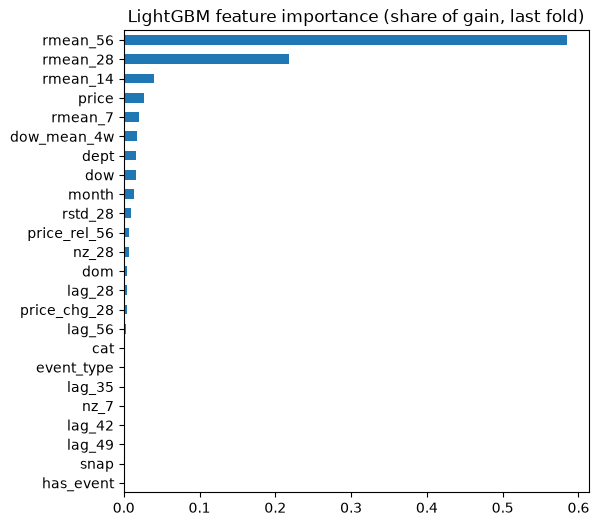

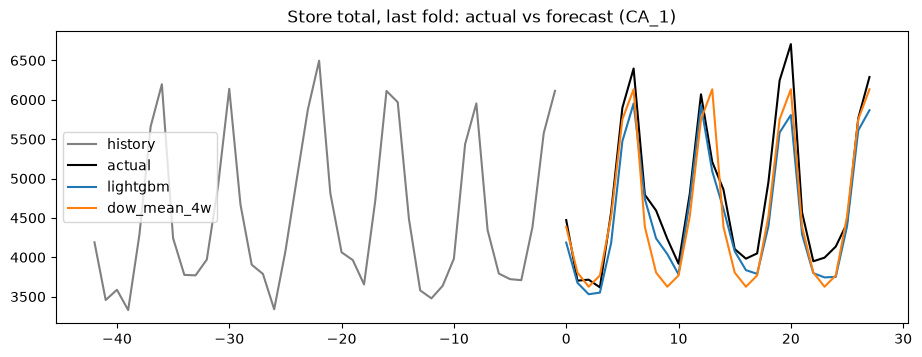

In [10]:
imp = pd.Series(last["model"].feature_importance("gain"), index=last["model"].feature_name())
imp = (imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(6, 6))
imp.plot.barh(ax=ax)
ax.set_title("LightGBM feature importance (share of gain, last fold)")
fig.savefig(FIG / "06_feature_importance.png", dpi=150, bbox_inches="tight")

o = last["origin"]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(-42, 0), Y64[:, o - 42:o].sum(axis=0), color="grey", label="history")
ax.plot(np.arange(H), Y64[:, o:o + H].sum(axis=0), color="black", label="actual")
ax.plot(np.arange(H), last["forecasts"]["lightgbm"].sum(axis=0), label="lightgbm")
ax.plot(np.arange(H), last["forecasts"]["dow_mean_4w"].sum(axis=0), label="dow_mean_4w")
ax.set_title(f"Store total, last fold: actual vs forecast ({STORE})")
ax.legend()
fig.savefig(FIG / "07_store_total_forecast.png", dpi=150, bbox_inches="tight")

In [11]:
# save per-series results for notebook 04 (error analysis)
act = pd.concat([
    pd.DataFrame({"id": ids, "fold": f, "actual_sum": Y64[:, o:o + H].sum(axis=1)})
    for f, o in enumerate(origins)
])
res.merge(act, on=["id", "fold"], how="left").to_parquet(REP / "results_per_series.parquet", index=False)

In [12]:
_ = last["model"].save_model(str(PROC / "lgbm_last_fold.txt"))

## Takeaways (fill in)
- LightGBM vs best baseline (weighted RMSSE, % change):
- Where it wins most (class / category), and where baselines still win:
- Top 5 features:
- Bias: over- or under-forecasting?
- Ideas to improve: more history, tune parameters, add item-level target encoding, per-class models, ensemble with TSB for intermittent series.